# 1 Data Loading and Initial Inspection

Key takeaways:
- 7 features and datetime, 69,680 rows.
- Timestamps are 15 minute intervals.
- There are no missing or duplicate timestamps.
- There are no missing values.

## 1.1 Libraries and Formatting

### 1.1.1 Packages

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

In [2]:
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
from src.figures_cfg import apply_theme, plot_feature_ts, plot_features_ts, plot_correlation_matrix, plot_seasonal, plot_seasonal_grid, plot_monthly_box

### 1.1.2 Theme

In [3]:
apply_theme()
PRIMARY = "#003366"
MUTED   = "#6E7888"
INK     = "#121826"
LIGHT   = "#F0F2F5"

### 1.1.3 Load Data

In [4]:
# Set date as index.
df = pd.read_csv(PROJECT_ROOT / "data" / "ETTm1.csv", parse_dates=["date"], index_col="date")

---

## 1.2 Data Shape and Head

In [5]:
# Count rows and columns.
df.shape

(69680, 7)

In [6]:
df.head()

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
date,,,,,,,
2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
2016-07-01 00:15:00,5.760,2.076,1.492,0.426,4.264,1.401,30.459999
2016-07-01 00:30:00,5.760,1.942,1.492,0.391,4.234,1.310,30.038000
2016-07-01 00:45:00,5.760,1.942,1.492,0.426,4.234,1.310,27.013000
2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001


## 1.3 Data Types

In [7]:
df.dtypes

HUFL    float64
HULL    float64
MUFL    float64
MULL    float64
LUFL    float64
LULL    float64
OT      float64
dtype: object

## 1.4 Date Validation

In [8]:
full_date_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq="15min")

assert all(full_date_range == df.index)

## 1.5 Missing Values

In [9]:
df.isnull().sum().sum()

np.int64(0)

In [10]:
df.describe()

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
count,69680.000000,69680.000000,69680.000000,69680.000000,69680.000000,69680.000000,69680.000000
mean,7.413993,2.261418,4.322226,0.896509,3.082888,0.857907,13.320642
std,7.082928,2.041293,6.829189,1.807239,1.174063,0.600440,8.564817
min,-23.242001,-5.693000,-26.367001,-6.041000,-1.188000,-1.371000,-4.221000
25%,5.827000,0.804000,3.305000,-0.284000,2.315000,0.670000,6.964000
50%,8.841000,2.210000,6.005000,0.959000,2.833000,0.975000,11.396000
75%,11.788000,3.684000,8.635000,2.203000,3.655000,1.218000,18.079000
max,24.180000,10.315000,18.087000,7.853000,8.498000,3.046000,46.007000


---

# 2 Descriptive Statistics

## 2.1 Correlation Matrix

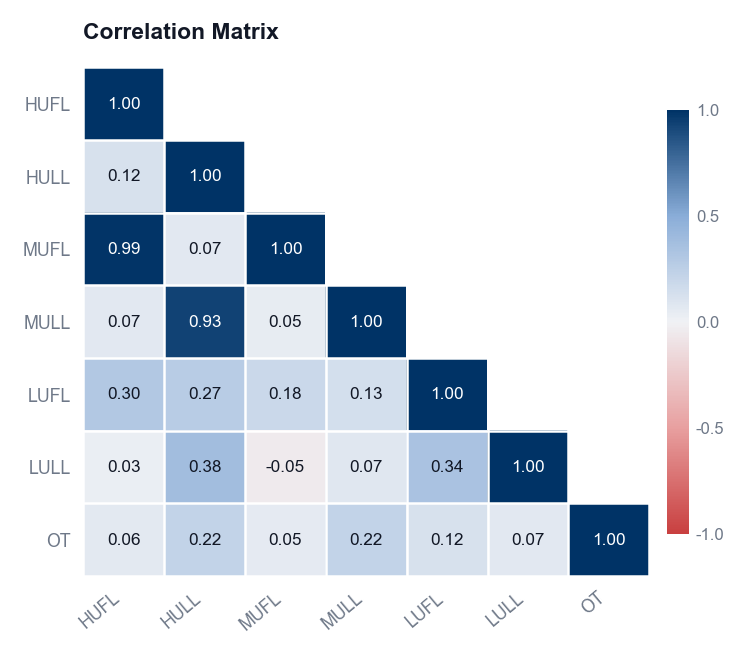

In [11]:
fig = plot_correlation_matrix(df, title="Correlation Matrix", mask_upper=True)
fig.savefig("../figures/eda/correlation-matrix.png")
plt.show()

---

# 3 Time Series Visualisation

## 3.1 Complete Time Series Plots

### 3.1.1 Predictors

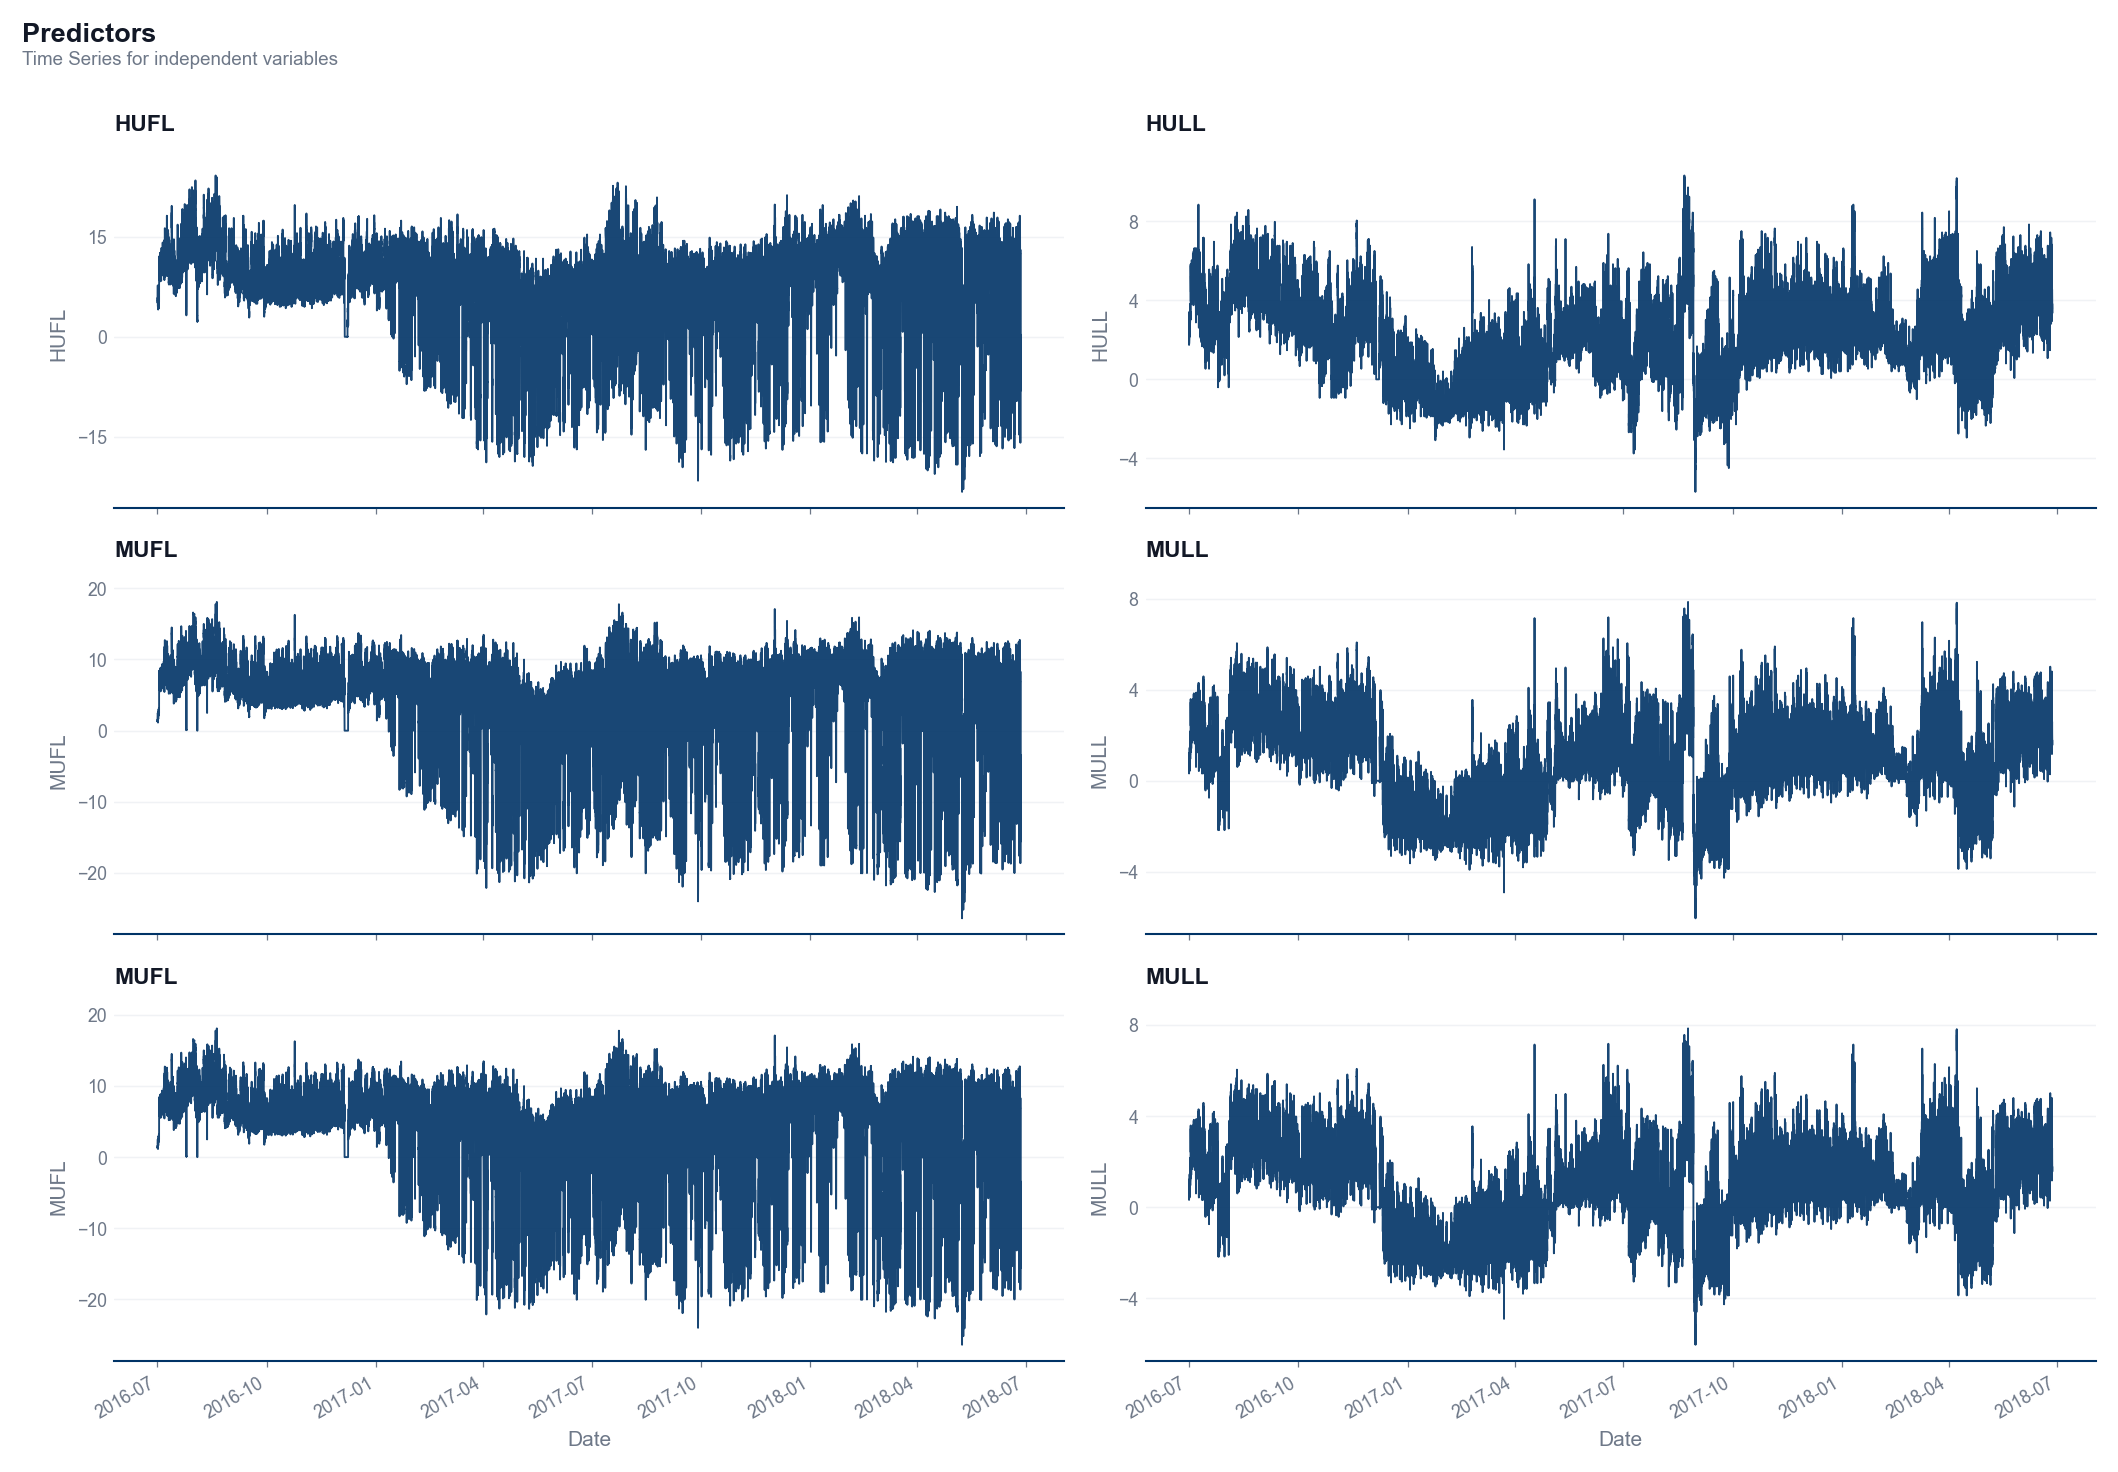

In [12]:
fig = plot_features_ts(df, ["HUFL", "HULL", "MUFL", "MULL", "MUFL", "MULL"], 3, 2, suptitle="Predictors", subtitle="Time Series for independent variables")
fig.savefig("../figures/eda/predictor-time-series.png")

### 3.1.2 Independent Variable

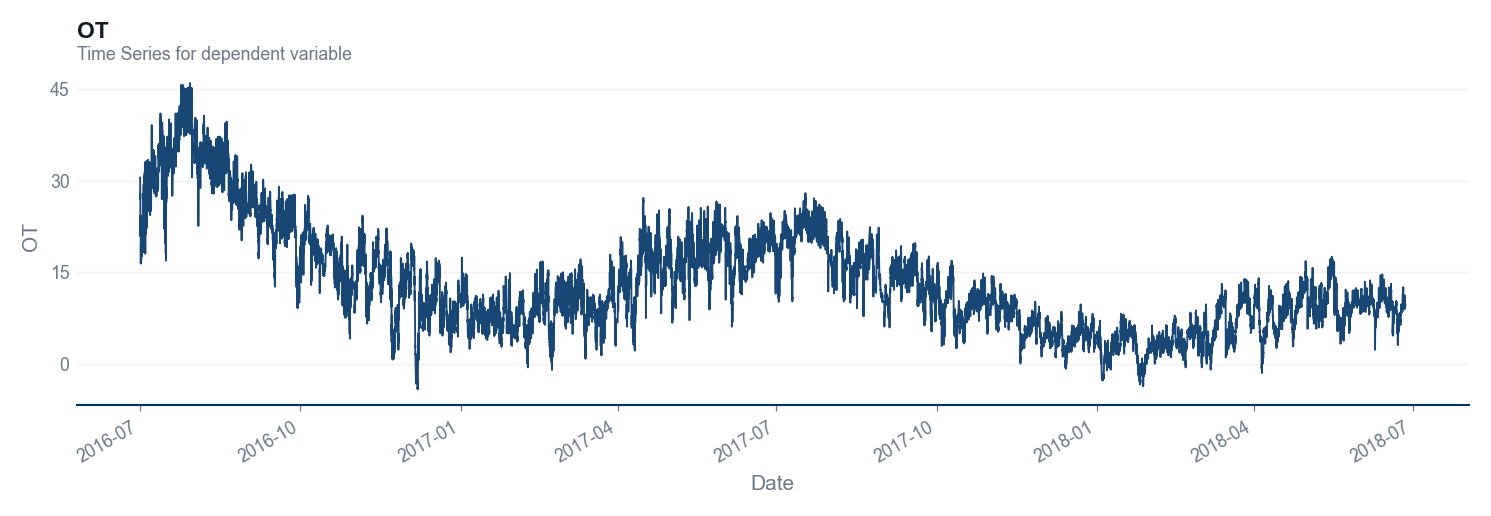

In [13]:
fig = plot_feature_ts(df, "OT", "OT", subtitle="Time Series for dependent variable")
fig.savefig("../figures/eda/target-time-series.png")

## 3.2 Seasonal Plots

### 3.2.1 Predictors

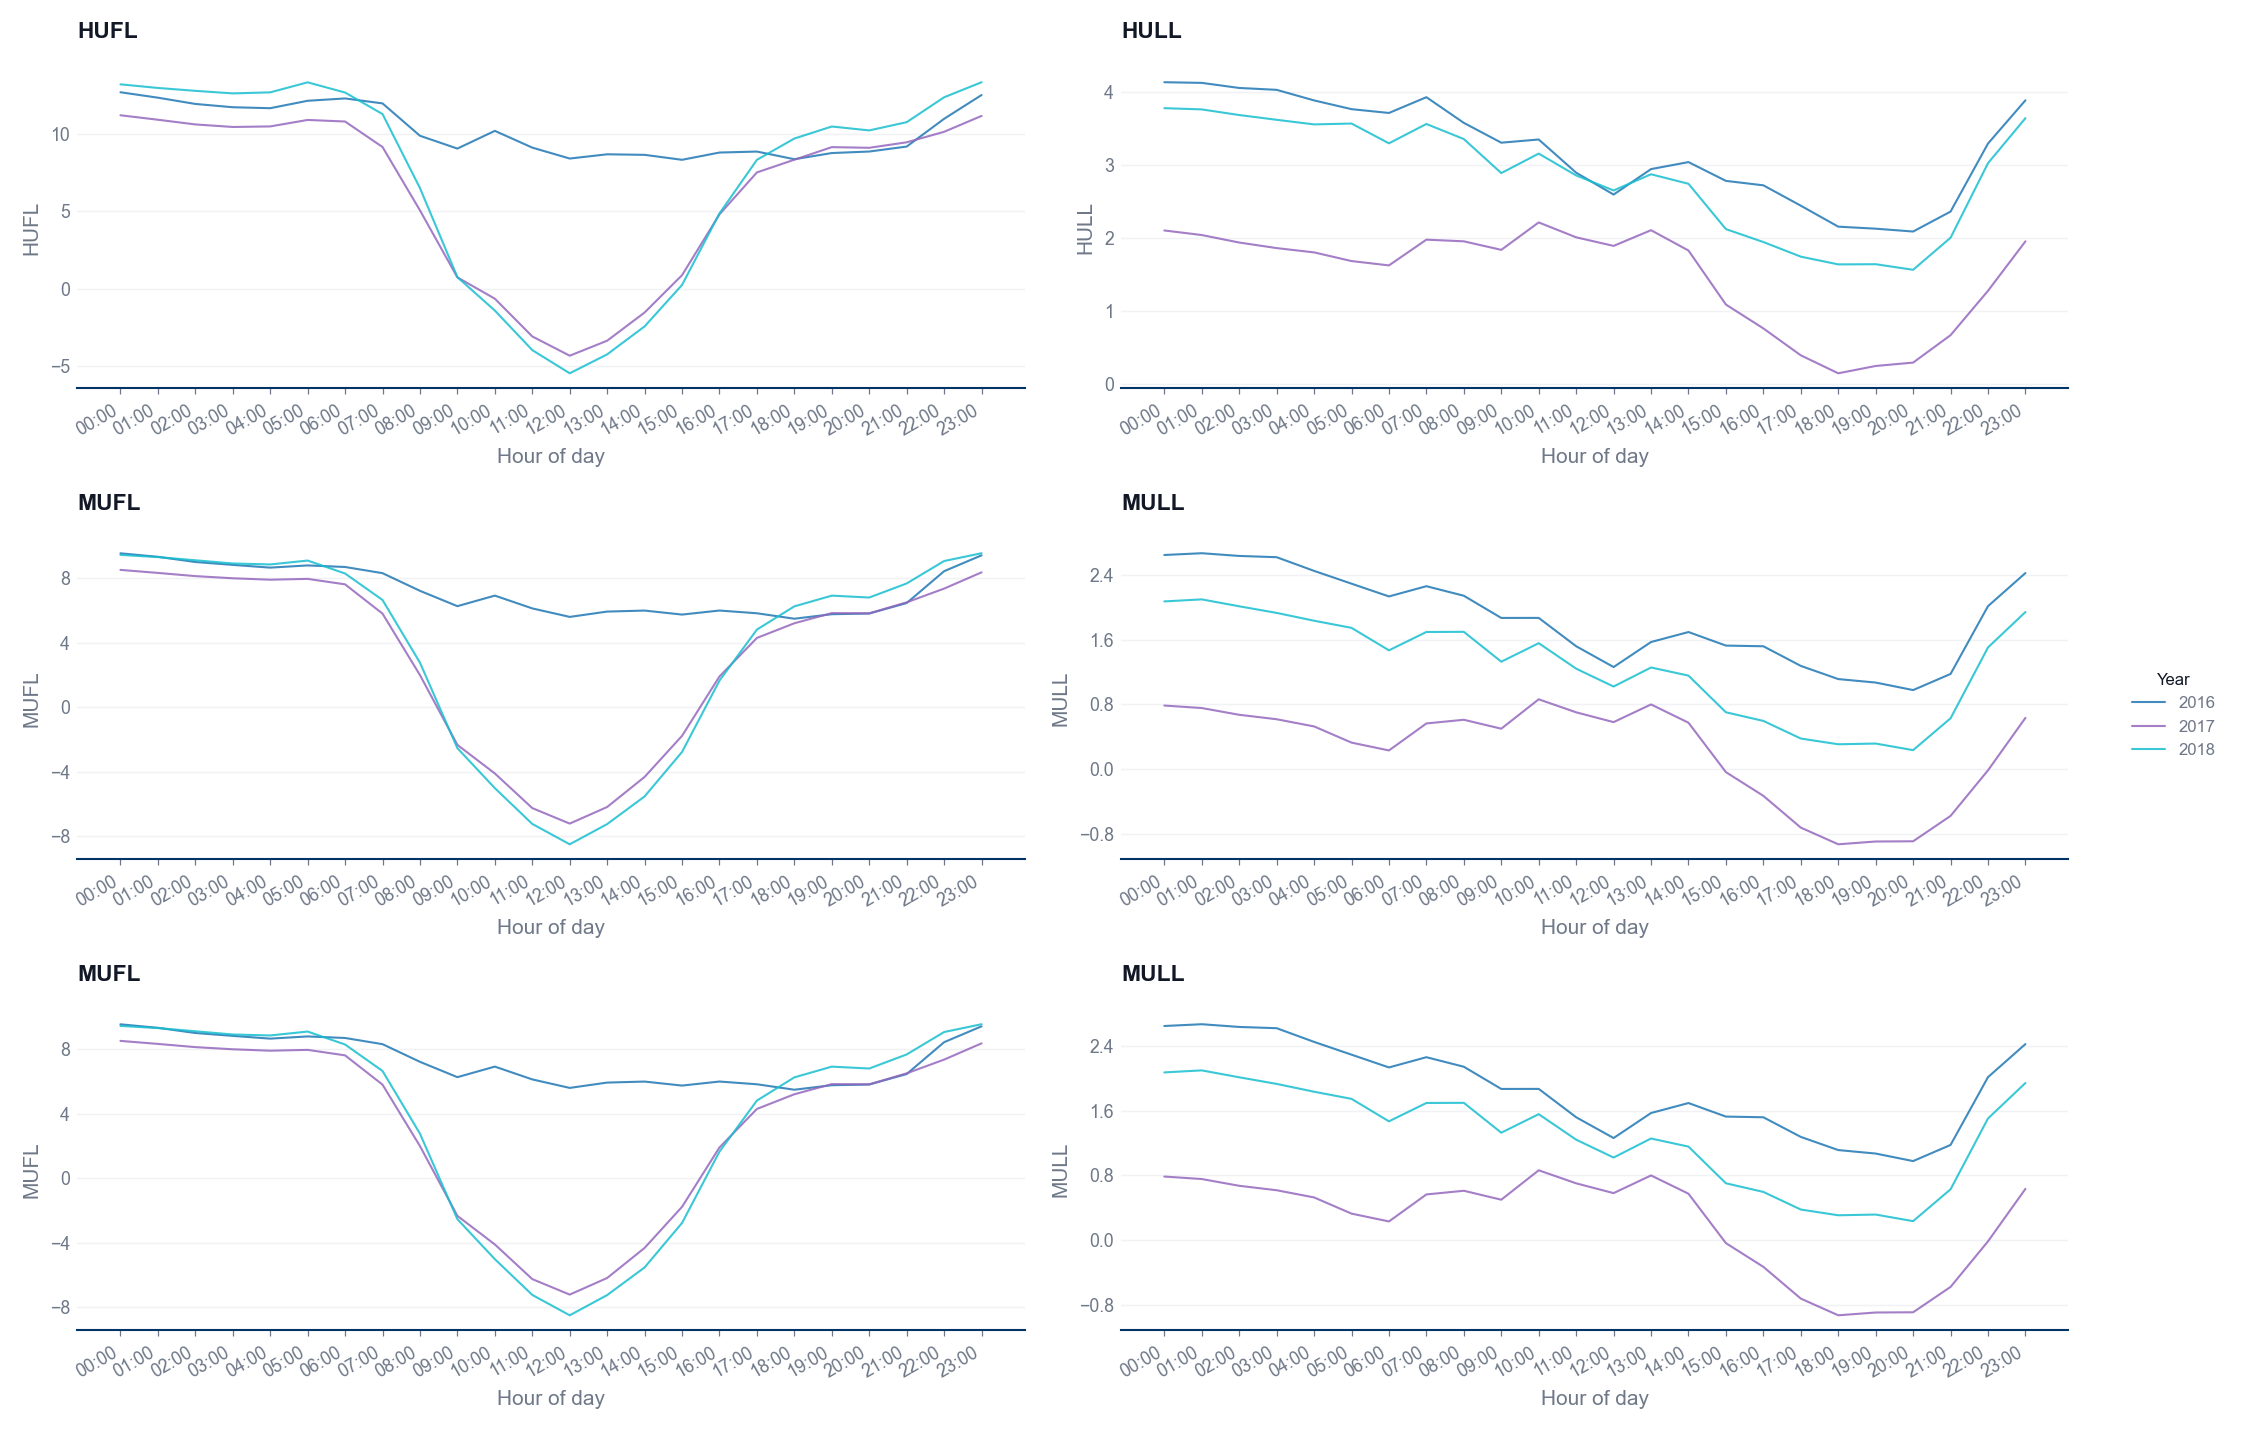

In [14]:
fig = plot_seasonal_grid(df, ["HUFL", "HULL", "MUFL", "MULL", "MUFL", "MULL"], season="year", period="hour", rows=3, cols=2)

### 3.2.2 Indepdent Variable

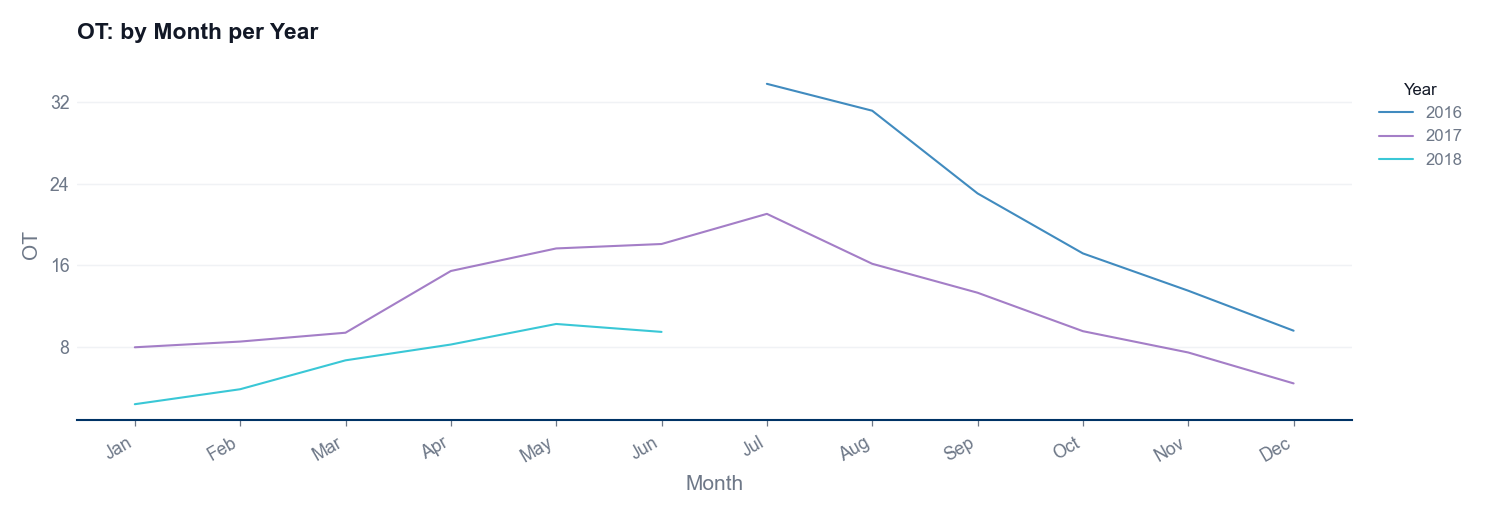

In [15]:
fig = plot_seasonal(df, "OT", season="year", period="month")

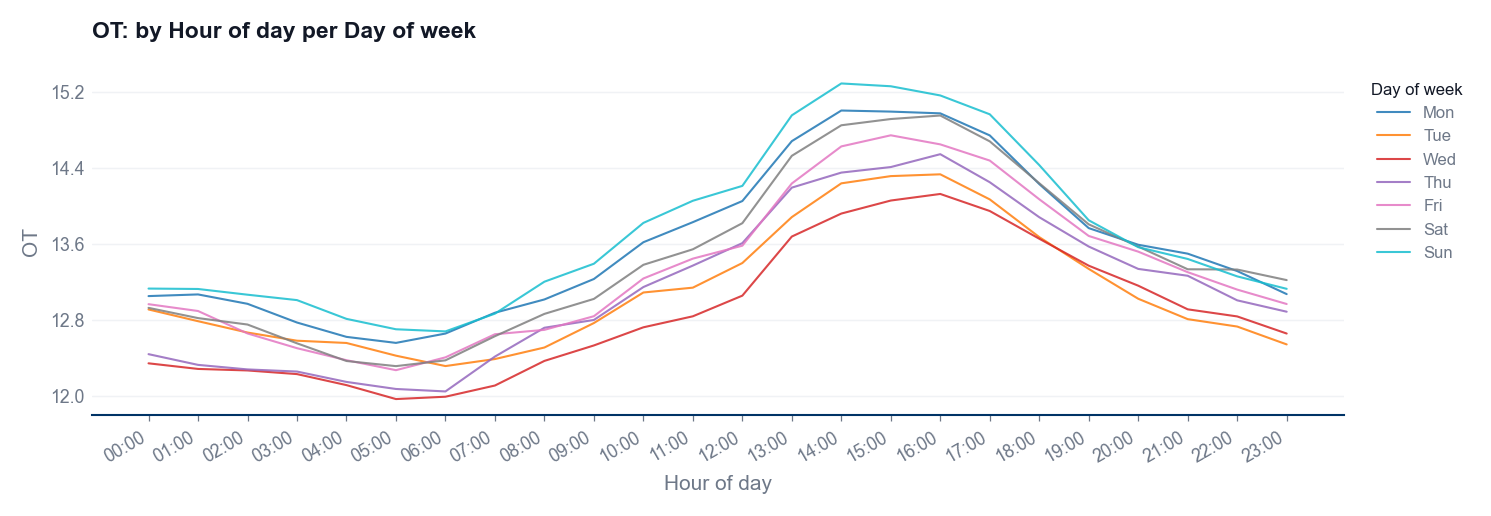

In [16]:
fig = plot_seasonal(df, "OT", season="dayofweek", period="hour")

## 3.3 Boxplots

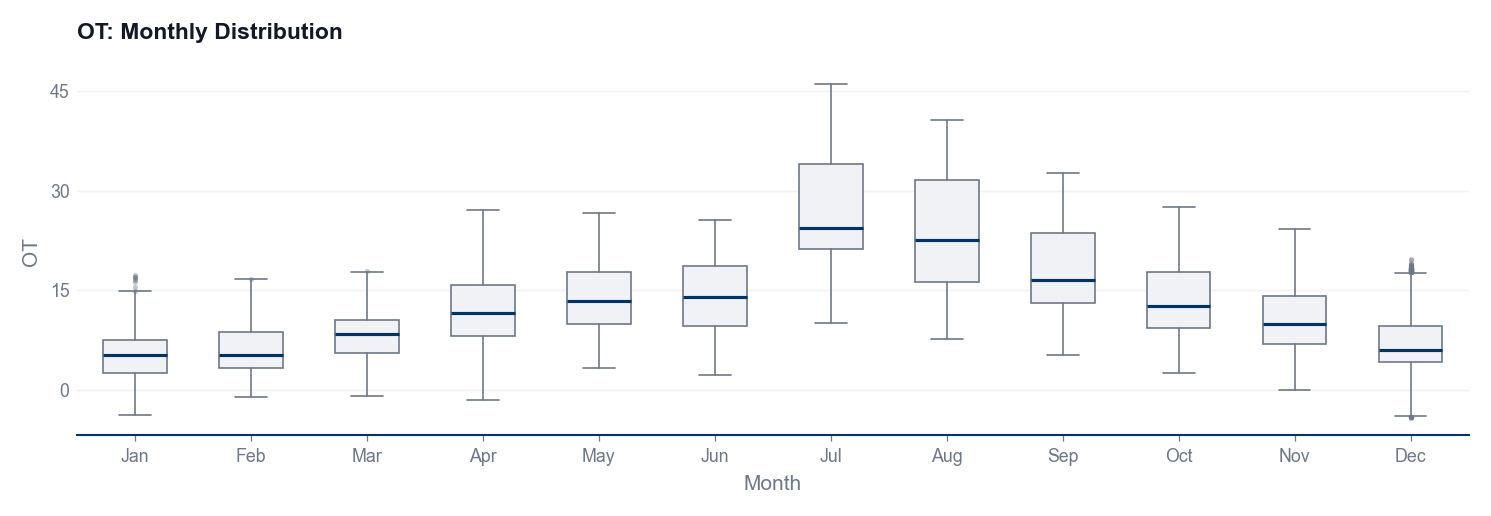

In [23]:
fig = plot_monthly_box(df, "OT")

---

# 4 Time Series Decomposition

---

# 5 Lag Analysis

## 5.1 ACF

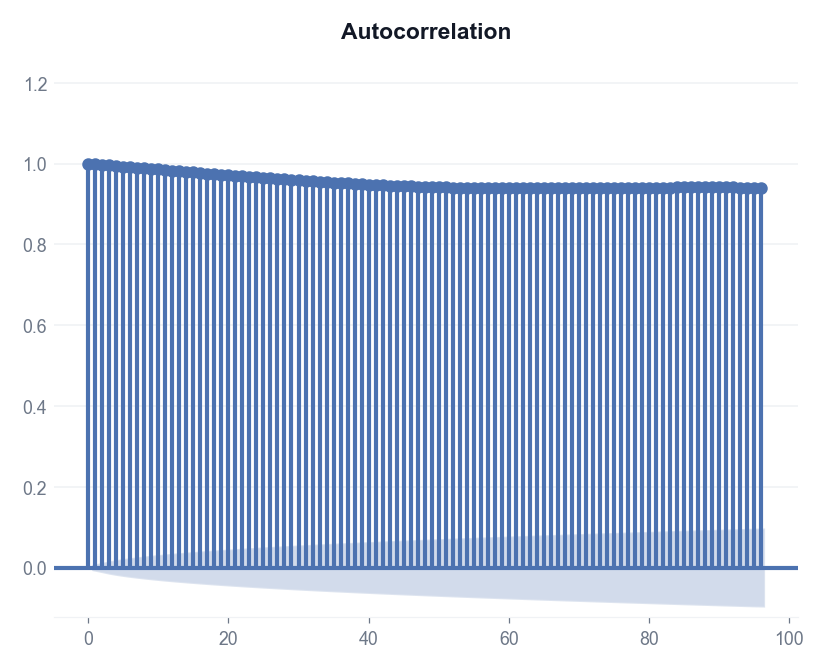

In [17]:
from statsmodels.graphics.tsaplots import plot_acf

# 96 lags = 1 day
acf_plot = plot_acf(df.OT, lags=96, auto_ylims=True)


ACF plot shows very high correlation to lagged values, and slow drop off suggests OT is not stationary.

## 5.2 PACF

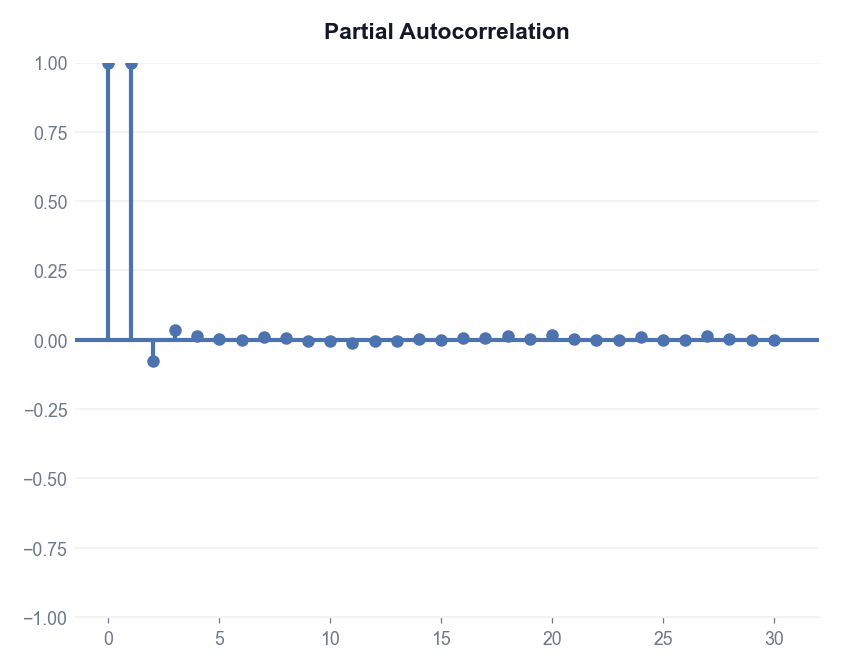

In [18]:
from statsmodels.graphics.tsaplots import plot_pacf

pacf_plot = plot_pacf(df.OT, lags=30)

PACF plot shows that only previous value has high correlation when using directly correlation to lagged values.

---

# 6 Stationarity Testing

---

# 7 Summary